In [16]:
"""
03_exploratory_data_analysis.ipynb
Phase 4: Exploratory Data Analysis (EDA)
Author: [Your Name]
Date: 2026-08-28
Description: Visualize and analyze the feature-engineered data
"""

# Install notebook dependencies when they are missing from the active kernel
%pip install -q matplotlib seaborn pandas numpy pyarrow

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
import warnings
warnings.filterwarnings('ignore')

# Set up plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['legend.fontsize'] = 12

# Add src to path
sys.path.append(str(Path.cwd().parent / 'src'))
from config import DATA_PROCESSED, RESULTS_FIGURES, RESULTS_TABLES

print("✅ All imports loaded successfully!")
print(f"Results figures path: {RESULTS_FIGURES}")
print(f"Results tables path: {RESULTS_TABLES}")

# Create results directories if they don't exist
RESULTS_FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS_TABLES.mkdir(parents=True, exist_ok=True)

Note: you may need to restart the kernel to use updated packages.
✅ All imports loaded successfully!
Results figures path: C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\figures
Results tables path: C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables


In [17]:
# Load data with features
print("Loading feature-engineered data...")

def load_feature_data(name):
    """Load feature data from Parquet, with CSV fallback."""
    parquet_path = DATA_PROCESSED / f'{name}_with_features.parquet'
    csv_path = DATA_PROCESSED / f'{name}_with_features.csv'
    try:
        return pd.read_parquet(parquet_path)
    except Exception as error:
        if not csv_path.exists():
            raise FileNotFoundError(f"Could not load {parquet_path} and fallback is missing: {csv_path}") from error
        print(f"Parquet unavailable for {name}; loading {csv_path.name}: {error}")
        return pd.read_csv(csv_path)

reddit_df   = load_feature_data('reddit')
x_df        = load_feature_data('twitter')          # ← CHANGED: 'twitter' not 'x'
combined_df = load_feature_data('combined')

# Normalize platform labels (safety for downstream comparisons)
reddit_df['platform']   = 'Reddit'
x_df['platform']        = 'X'
combined_df['platform'] = combined_df['platform'].replace({'Twitter': 'X'})

print(f"✅ Reddit data: {len(reddit_df):,} rows, {len(reddit_df.columns)} columns")
print(f"✅ X data: {len(x_df):,} rows, {len(x_df.columns)} columns")
print(f"✅ Combined data: {len(combined_df):,} rows, {len(combined_df.columns)} columns")

# Display column names
print("\nCombined data columns:")
print(combined_df.columns.tolist())

# Quick sanity check that key features exist
required_features = ['fk_grade', 'ttr', 'rigor_score', 'sentiment_score',
                     'engagement_normalized', 'link_count', 'evidentiary_count']
missing = [c for c in required_features if c not in combined_df.columns]
if missing:
    print(f"\n⚠️ Missing expected features: {missing}")
else:
    print("\n✅ All required features present")

Loading feature-engineered data...
✅ Reddit data: 5,000 rows, 62 columns
✅ X data: 5,000 rows, 54 columns
✅ Combined data: 10,000 rows, 72 columns

Combined data columns:
['comment_id', 'self_text', 'created_time', 'author_name', 'subreddit', 'score', 'ups', 'downs', 'controversiality', 'post_id', 'post_title', 'user_is_verified', 'user_account_created_time', 'user_total_karma', 'user_comment_karma', 'post_score', 'post_upvote_ratio', 'account_age_days', 'timestamp', 'year', 'month', 'day', 'hour', 'day_of_week', 'is_weekend', 'hours_since_event', 'hour_bin', 'clean_text', 'tokens', 'word_count', 'language', 'platform', 'engagement_raw', 'engagement_log', 'engagement_normalized', 'fk_grade', 'fk_ease', 'ttr', 'avg_word_len', 'avg_syllables', 'gunning_fog', 'coleman_liau', 'automated_readability', 'link_count', 'avg_domain_credibility', 'rigor_score', 'unique_domains', 'has_link', 'evidentiary_count', 'weak_count', 'rigor_lexicon_score', 'evidence_density', 'sentiment_score', 'sentiment

In [18]:
"""
DATA OVERVIEW
"""

# Basic info
print("=== DATA OVERVIEW ===\n")

# Print summary statistics for key features
key_features = ['fk_grade', 'ttr', 'rigor_score', 'sentiment_score', 
                'engagement_normalized', 'word_count', 'link_count']

print("Reddit - Key Features Summary:")
display(reddit_df[key_features].describe())

print("\nX - Key Features Summary:")
display(x_df[key_features].describe())

# Save summary tables
reddit_summary = reddit_df[key_features].describe()
x_summary = x_df[key_features].describe()

reddit_summary.to_csv(RESULTS_TABLES / 'reddit_summary_stats.csv')
x_summary.to_csv(RESULTS_TABLES / 'x_summary_stats.csv')
print(f"✅ Summary tables saved to {RESULTS_TABLES}")

=== DATA OVERVIEW ===

Reddit - Key Features Summary:


,fk_grade,ttr,rigor_score,sentiment_score,engagement_normalized,word_count,link_count
count,5000.000000,5000.000000,5000.000000,5000.0,5000.000000,5000.000000,5000.000000
mean,8.491434,0.863650,0.048130,0.0,0.227824,23.829000,0.101200
std,4.170491,0.110190,0.244739,0.0,0.182306,29.698568,0.530862
min,-2.230000,0.347826,0.000000,0.0,0.000000,5.000000,0.000000
25%,5.864034,0.791667,0.000000,0.0,0.077898,9.000000,0.000000
50%,7.889865,0.878788,0.000000,0.0,0.201364,16.000000,0.000000
75%,10.471781,0.950000,0.000000,0.0,0.342155,28.000000,0.000000
max,52.785455,1.000000,4.300000,0.0,1.000000,634.000000,8.000000



X - Key Features Summary:


,fk_grade,ttr,rigor_score,sentiment_score,engagement_normalized,word_count,link_count
count,5000.000000,5000.000000,5000.000000,5000.0,5000.000000,5000.00000,5000.000000
mean,10.893749,0.880622,0.198240,0.0,0.416967,21.75660,0.495600
std,4.528314,0.096778,0.238143,0.0,0.115847,21.82895,0.595358
min,1.468571,0.333333,0.000000,0.0,0.143638,5.00000,0.000000
25%,7.773333,0.829787,0.000000,0.0,0.332051,13.00000,0.000000
50%,10.208889,0.892857,0.000000,0.0,0.406227,19.00000,0.000000
75%,13.117279,0.950000,0.400000,0.0,0.489323,25.00000,1.000000
max,56.358248,1.000000,3.200000,0.0,1.000000,520.00000,8.000000


✅ Summary tables saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables


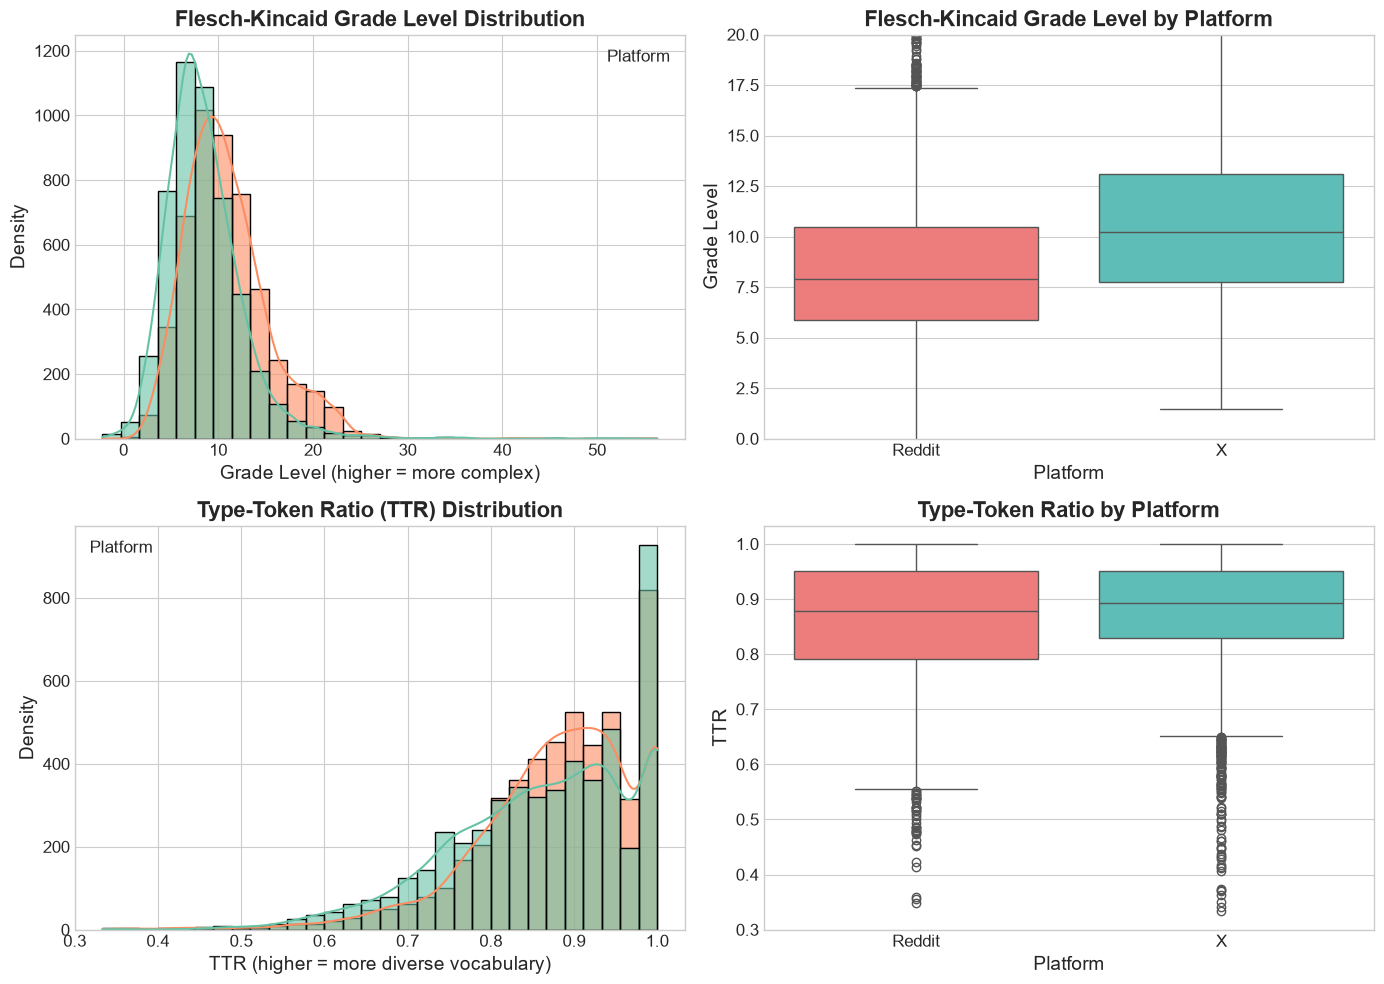

✅ Figure 1 saved: figure1_lexical_complexity.png


In [19]:
"""
FIGURE 1: LEXICAL COMPLEXITY DISTRIBUTIONS
Compare Flesch-Kincaid Grade and TTR across platforms
"""

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Flesch-Kincaid Grade Distribution
ax = axes[0, 0]
sns.histplot(data=combined_df, x='fk_grade', hue='platform', kde=True, bins=30, alpha=0.6, ax=ax)
ax.set_title('Flesch-Kincaid Grade Level Distribution', fontweight='bold')
ax.set_xlabel('Grade Level (higher = more complex)')
ax.set_ylabel('Density')
ax.legend(title='Platform')

# Boxplot for Flesch-Kincaid
ax = axes[0, 1]
sns.boxplot(data=combined_df, x='platform', y='fk_grade', ax=ax, palette=['#FF6B6B', '#4ECDC4'])
ax.set_title('Flesch-Kincaid Grade Level by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Grade Level')
ax.set_ylim(0, 20)

# TTR Distribution
ax = axes[1, 0]
sns.histplot(data=combined_df, x='ttr', hue='platform', kde=True, bins=30, alpha=0.6, ax=ax)
ax.set_title('Type-Token Ratio (TTR) Distribution', fontweight='bold')
ax.set_xlabel('TTR (higher = more diverse vocabulary)')
ax.set_ylabel('Density')
ax.legend(title='Platform')

# Boxplot for TTR
ax = axes[1, 1]
sns.boxplot(data=combined_df, x='platform', y='ttr', ax=ax, palette=['#FF6B6B', '#4ECDC4'])
ax.set_title('Type-Token Ratio by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('TTR')

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'figure1_lexical_complexity.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 1 saved: figure1_lexical_complexity.png")

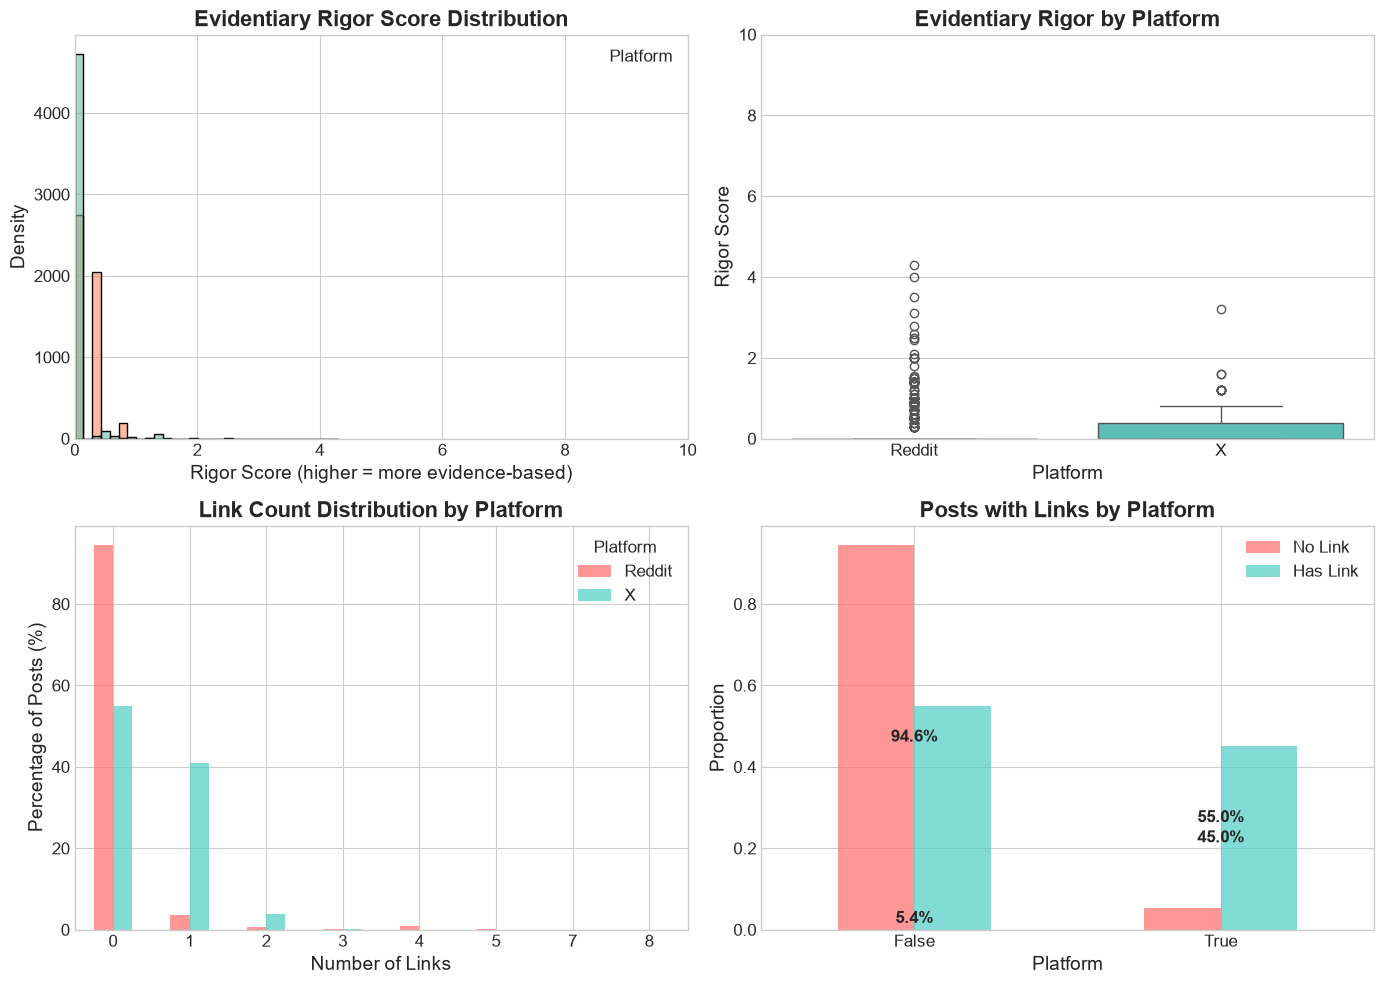

✅ Figure 2 saved: figure2_evidentiary_rigor.png


In [20]:
"""
FIGURE 2: EVIDENTIARY RIGOR DISTRIBUTIONS
Compare rigor scores and link usage across platforms
"""

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Rigor Score Distribution
ax = axes[0, 0]
sns.histplot(data=combined_df, x='rigor_score', hue='platform', kde=False, bins=30, alpha=0.6, ax=ax)
ax.set_title('Evidentiary Rigor Score Distribution', fontweight='bold')
ax.set_xlabel('Rigor Score (higher = more evidence-based)')
ax.set_ylabel('Density')
ax.legend(title='Platform')
ax.set_xlim(0, 10)

# Boxplot for Rigor Score
ax = axes[0, 1]
sns.boxplot(data=combined_df, x='platform', y='rigor_score', ax=ax, palette=['#FF6B6B', '#4ECDC4'])
ax.set_title('Evidentiary Rigor by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Rigor Score')
ax.set_ylim(0, 10)

# Link Count Distribution
ax = axes[1, 0]
link_counts = combined_df.groupby(['platform', 'link_count']).size().unstack(fill_value=0)
link_counts_pct = link_counts.div(link_counts.sum(axis=1), axis=0) * 100
link_counts_pct.T.plot(kind='bar', ax=ax, color=['#FF6B6B', '#4ECDC4'], alpha=0.7)
ax.set_title('Link Count Distribution by Platform', fontweight='bold')
ax.set_xlabel('Number of Links')
ax.set_ylabel('Percentage of Posts (%)')
ax.legend(title='Platform')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Posts with and without links
ax = axes[1, 1]
has_link = combined_df.groupby('platform')['has_link'].value_counts(normalize=True).unstack(fill_value=0)
has_link.T.plot(kind='bar', ax=ax, color=['#FF6B6B', '#4ECDC4'], alpha=0.7)
ax.set_title('Posts with Links by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Proportion')
ax.legend(['No Link', 'Has Link'])
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Add percentages on bars
for i, platform in enumerate(has_link.index):
    for j, val in enumerate(has_link.loc[platform]):
        ax.text(i, val / 2, f'{val * 100:.1f}%', ha='center', va='center', fontweight='bold')

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'figure2_evidentiary_rigor.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 2 saved: figure2_evidentiary_rigor.png")

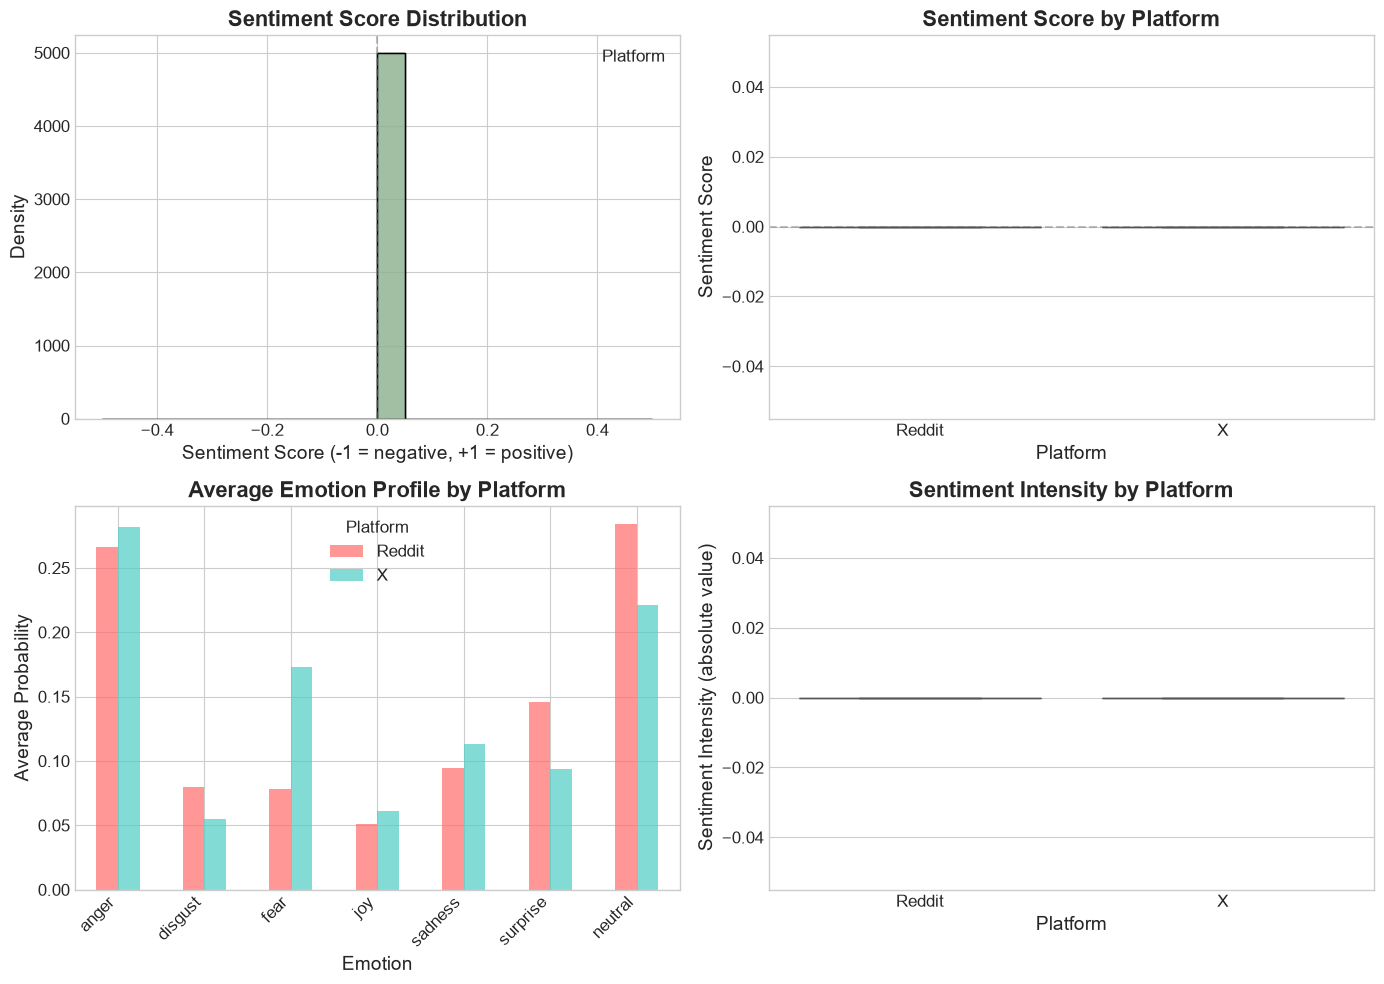

✅ Figure 3 saved: figure3_sentiment_emotion.png


In [21]:
"""
FIGURE 3: SENTIMENT AND EMOTION DISTRIBUTIONS
Compare sentiment and emotion profiles across platforms
"""

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Sentiment Distribution
ax = axes[0, 0]
sns.histplot(data=combined_df, x='sentiment_score', hue='platform', kde=False, bins=20, alpha=0.6, ax=ax)
ax.set_title('Sentiment Score Distribution', fontweight='bold')
ax.set_xlabel('Sentiment Score (-1 = negative, +1 = positive)')
ax.set_ylabel('Density')
ax.legend(title='Platform')
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

# Sentiment Boxplot
ax = axes[0, 1]
sns.boxplot(data=combined_df, x='platform', y='sentiment_score', ax=ax, palette=['#FF6B6B', '#4ECDC4'])
ax.set_title('Sentiment Score by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Sentiment Score')
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)

# Emotion Profiles (average emotions per platform)
ax = axes[1, 0]
emotion_cols = ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'neutral']
emotion_means = combined_df.groupby('platform')[emotion_cols].mean()
emotion_means.T.plot(kind='bar', ax=ax, color=['#FF6B6B', '#4ECDC4'], alpha=0.7)
ax.set_title('Average Emotion Profile by Platform', fontweight='bold')
ax.set_xlabel('Emotion')
ax.set_ylabel('Average Probability')
ax.legend(title='Platform')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# Sentiment Intensity
ax = axes[1, 1]
combined_df['sentiment_intensity'] = np.abs(combined_df['sentiment_score'])
sns.boxplot(data=combined_df, x='platform', y='sentiment_intensity', ax=ax, palette=['#FF6B6B', '#4ECDC4'])
ax.set_title('Sentiment Intensity by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Sentiment Intensity (absolute value)')

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'figure3_sentiment_emotion.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 3 saved: figure3_sentiment_emotion.png")

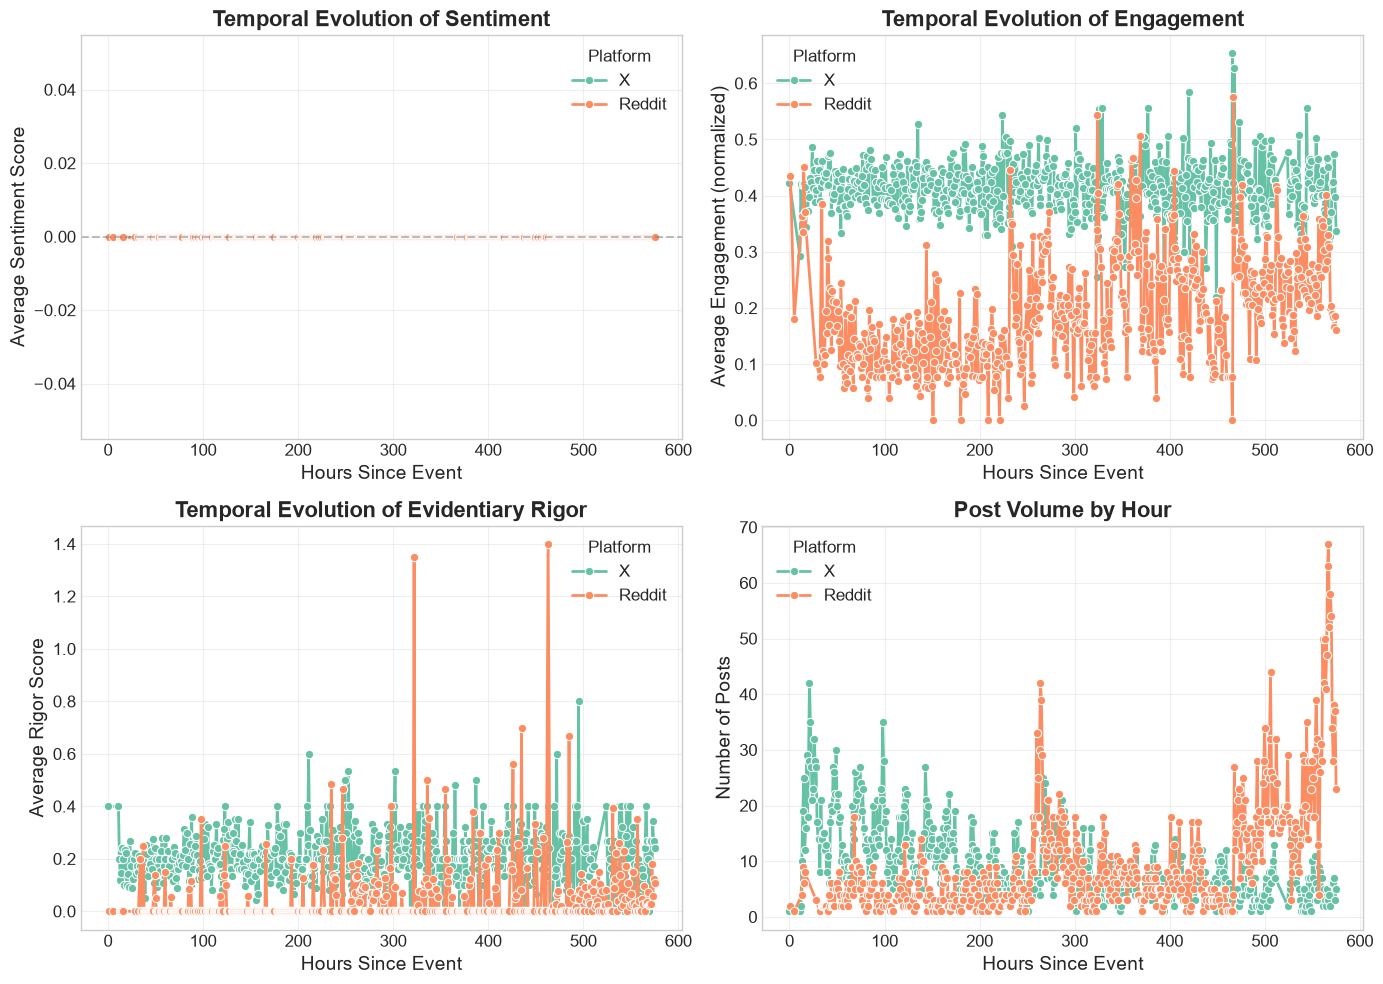

✅ Figure 4 saved: figure4_temporal_patterns.png


In [22]:
"""
FIGURE 4: TEMPORAL PATTERNS
Time-series analysis of sentiment and engagement
"""

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Temporal Sentiment Evolution
ax = axes[0, 0]
hourly_sentiment = combined_df.groupby(['hour_bin', 'platform'])['sentiment_score'].mean().reset_index()
sns.lineplot(data=hourly_sentiment, x='hour_bin', y='sentiment_score', hue='platform', 
             marker='o', ax=ax, linewidth=2, markersize=6)
ax.set_title('Temporal Evolution of Sentiment', fontweight='bold')
ax.set_xlabel('Hours Since Event')
ax.set_ylabel('Average Sentiment Score')
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax.legend(title='Platform')
ax.grid(True, alpha=0.3)

# Temporal Engagement
ax = axes[0, 1]
hourly_engagement = combined_df.groupby(['hour_bin', 'platform'])['engagement_normalized'].mean().reset_index()
sns.lineplot(data=hourly_engagement, x='hour_bin', y='engagement_normalized', hue='platform',
             marker='o', ax=ax, linewidth=2, markersize=6)
ax.set_title('Temporal Evolution of Engagement', fontweight='bold')
ax.set_xlabel('Hours Since Event')
ax.set_ylabel('Average Engagement (normalized)')
ax.legend(title='Platform')
ax.grid(True, alpha=0.3)

# Temporal Rigor
ax = axes[1, 0]
hourly_rigor = combined_df.groupby(['hour_bin', 'platform'])['rigor_score'].mean().reset_index()
sns.lineplot(data=hourly_rigor, x='hour_bin', y='rigor_score', hue='platform',
             marker='o', ax=ax, linewidth=2, markersize=6)
ax.set_title('Temporal Evolution of Evidentiary Rigor', fontweight='bold')
ax.set_xlabel('Hours Since Event')
ax.set_ylabel('Average Rigor Score')
ax.legend(title='Platform')
ax.grid(True, alpha=0.3)

# Post Volume by Hour
ax = axes[1, 1]
hourly_volume = combined_df.groupby(['hour_bin', 'platform']).size().reset_index(name='count')
sns.lineplot(data=hourly_volume, x='hour_bin', y='count', hue='platform',
             marker='o', ax=ax, linewidth=2, markersize=6)
ax.set_title('Post Volume by Hour', fontweight='bold')
ax.set_xlabel('Hours Since Event')
ax.set_ylabel('Number of Posts')
ax.legend(title='Platform')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'figure4_temporal_patterns.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 4 saved: figure4_temporal_patterns.png")

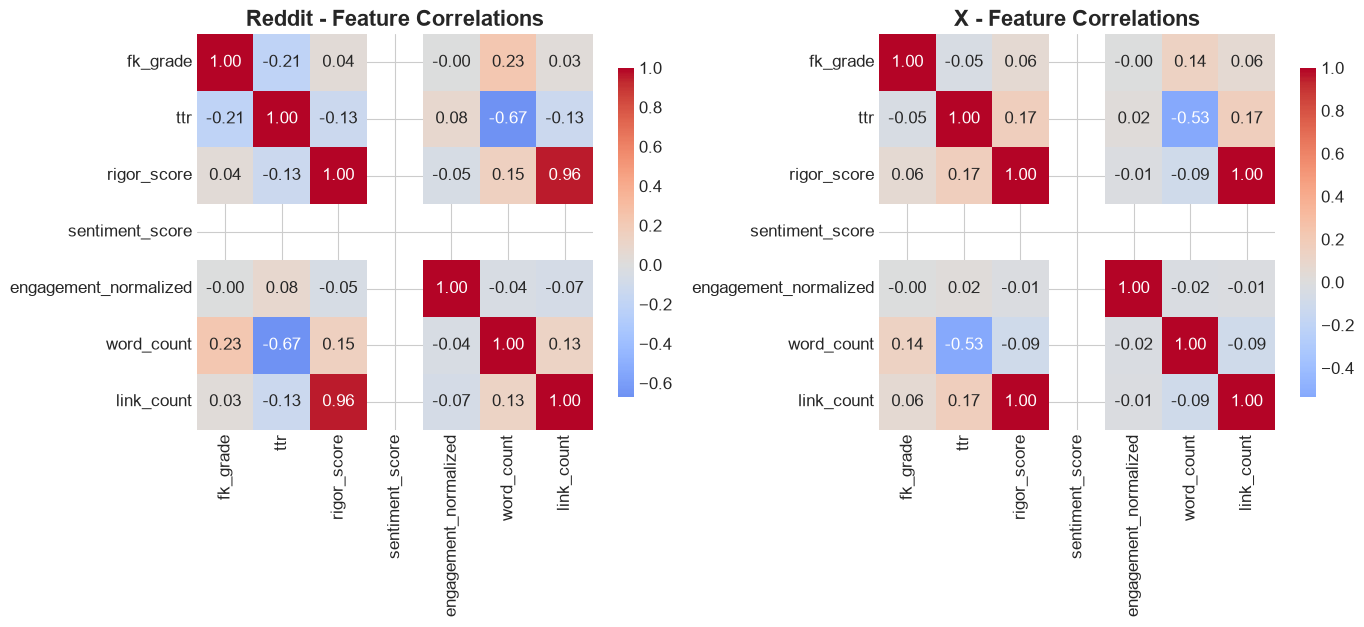

✅ Figure 5 saved: figure5_correlation_matrices.png
✅ Correlation matrices saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables


In [23]:
"""
FIGURE 5: CORRELATION MATRICES
Compare feature correlations within each platform
"""

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Select features for correlation
corr_features = ['fk_grade', 'ttr', 'rigor_score', 'sentiment_score', 
                 'engagement_normalized', 'word_count', 'link_count']

# Reddit correlation
reddit_corr = reddit_df[corr_features].corr()
sns.heatmap(reddit_corr, annot=True, cmap='coolwarm', center=0, 
            square=True, ax=axes[0], fmt='.2f', cbar_kws={'shrink': 0.8})
axes[0].set_title('Reddit - Feature Correlations', fontweight='bold')

# X correlation
x_corr = x_df[corr_features].corr()
sns.heatmap(x_corr, annot=True, cmap='coolwarm', center=0, 
            square=True, ax=axes[1], fmt='.2f', cbar_kws={'shrink': 0.8})
axes[1].set_title('X - Feature Correlations', fontweight='bold')

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'figure5_correlation_matrices.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 5 saved: figure5_correlation_matrices.png")

# Save correlation matrices
reddit_corr.to_csv(RESULTS_TABLES / 'reddit_correlation.csv')
x_corr.to_csv(RESULTS_TABLES / 'x_correlation.csv')
print(f"✅ Correlation matrices saved to {RESULTS_TABLES}")

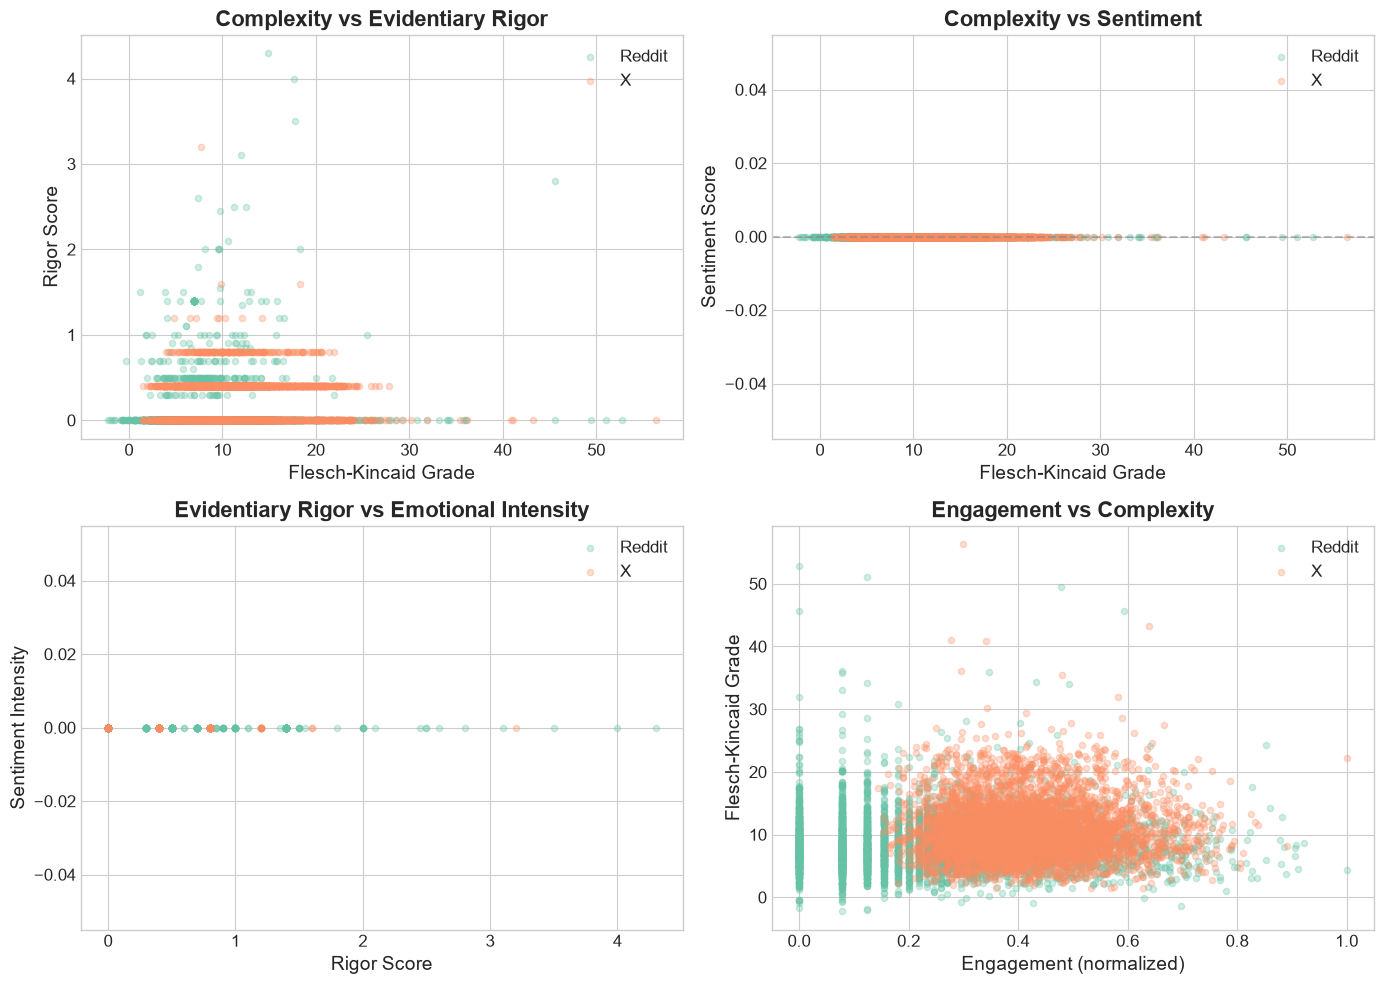

✅ Figure 6 saved: figure6_feature_relationships.png


In [24]:
"""
FIGURE 6: KEY RELATIONSHIPS
Scatter plots showing relationships between key variables
"""

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Complexity vs Rigor
ax = axes[0, 0]
for platform in combined_df['platform'].unique():
    subset = combined_df[combined_df['platform'] == platform]
    ax.scatter(subset['fk_grade'], subset['rigor_score'], alpha=0.3, label=platform, s=20)
ax.set_xlabel('Flesch-Kincaid Grade')
ax.set_ylabel('Rigor Score')
ax.set_title('Complexity vs Evidentiary Rigor', fontweight='bold')
ax.legend()

# Complexity vs Sentiment
ax = axes[0, 1]
for platform in combined_df['platform'].unique():
    subset = combined_df[combined_df['platform'] == platform]
    ax.scatter(subset['fk_grade'], subset['sentiment_score'], alpha=0.3, label=platform, s=20)
ax.set_xlabel('Flesch-Kincaid Grade')
ax.set_ylabel('Sentiment Score')
ax.set_title('Complexity vs Sentiment', fontweight='bold')
ax.legend()
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)

# Rigor vs Sentiment Intensity
ax = axes[1, 0]
combined_df['sentiment_intensity'] = np.abs(combined_df['sentiment_score'])
for platform in combined_df['platform'].unique():
    subset = combined_df[combined_df['platform'] == platform]
    ax.scatter(subset['rigor_score'], subset['sentiment_intensity'], alpha=0.3, label=platform, s=20)
ax.set_xlabel('Rigor Score')
ax.set_ylabel('Sentiment Intensity')
ax.set_title('Evidentiary Rigor vs Emotional Intensity', fontweight='bold')
ax.legend()

# Engagement vs Complexity
ax = axes[1, 1]
for platform in combined_df['platform'].unique():
    subset = combined_df[combined_df['platform'] == platform]
    ax.scatter(subset['engagement_normalized'], subset['fk_grade'], alpha=0.3, label=platform, s=20)
ax.set_xlabel('Engagement (normalized)')
ax.set_ylabel('Flesch-Kincaid Grade')
ax.set_title('Engagement vs Complexity', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'figure6_feature_relationships.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 6 saved: figure6_feature_relationships.png")

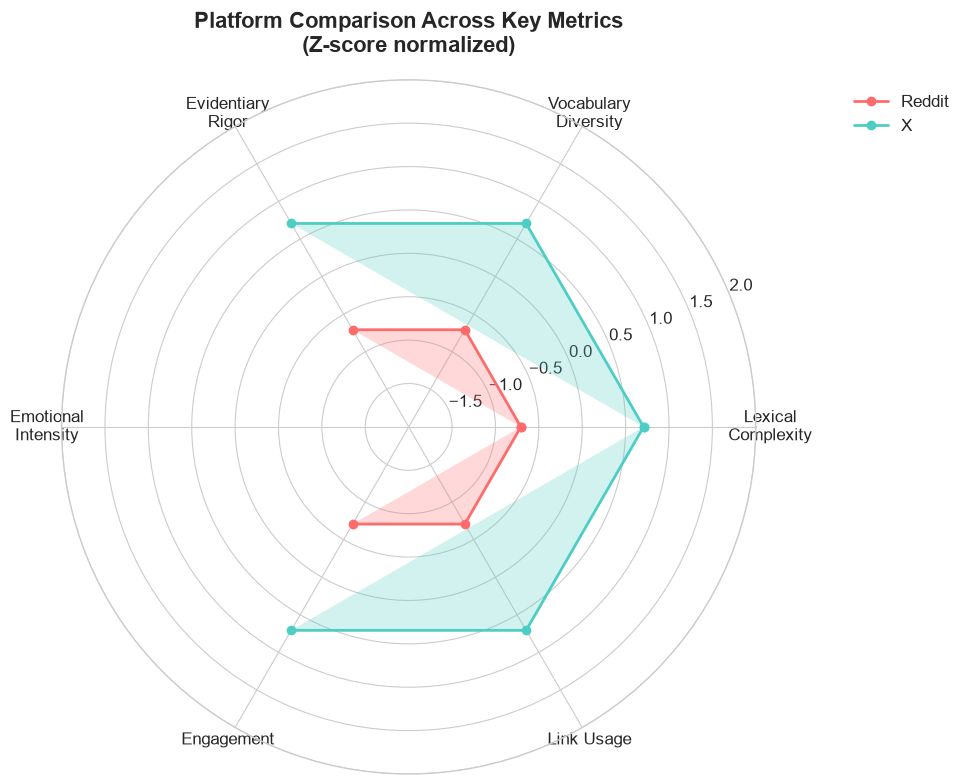

✅ Figure 7 saved: figure7_platform_radar.png


In [25]:
"""
FIGURE 7: PLATFORM COMPARISON RADAR CHART
Visual comparison of platforms across key metrics
"""

from math import pi

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': 'polar'})

# Select metrics for radar chart
metrics = ['fk_grade', 'ttr', 'rigor_score', 'sentiment_intensity', 
           'engagement_normalized', 'link_count']

# Normalize metrics (z-score)
def normalize_metrics(df, metrics):
    normalized = df[metrics].copy()
    for metric in metrics:
        normalized[metric] = (normalized[metric] - normalized[metric].mean()) / normalized[metric].std()
    return normalized

# Get mean values per platform
reddit_means = reddit_df[metrics].mean()
x_means = x_df[metrics].mean()

# Normalize
all_means = pd.DataFrame({'Reddit': reddit_means, 'X': x_means})
all_means_normalized = (all_means - all_means.mean(axis=1).values.reshape(-1, 1)) / all_means.std(axis=1).values.reshape(-1, 1)

# Set up radar chart
angles = [n / float(len(metrics)) * 2 * pi for n in range(len(metrics))]
angles += angles[:1]  # Close the loop

# Plot
ax.plot(angles, all_means_normalized['Reddit'].tolist() + [all_means_normalized['Reddit'].iloc[0]], 
        'o-', linewidth=2, label='Reddit', color='#FF6B6B')
ax.fill(angles, all_means_normalized['Reddit'].tolist() + [all_means_normalized['Reddit'].iloc[0]], 
        alpha=0.25, color='#FF6B6B')

ax.plot(angles, all_means_normalized['X'].tolist() + [all_means_normalized['X'].iloc[0]], 
        'o-', linewidth=2, label='X', color='#4ECDC4')
ax.fill(angles, all_means_normalized['X'].tolist() + [all_means_normalized['X'].iloc[0]], 
        alpha=0.25, color='#4ECDC4')

# Set labels
ax.set_xticks(angles[:-1])
ax.set_xticklabels(['Lexical\nComplexity', 'Vocabulary\nDiversity', 'Evidentiary\nRigor', 
                    'Emotional\nIntensity', 'Engagement', 'Link Usage'])
ax.set_ylim(-2, 2)
ax.set_title('Platform Comparison Across Key Metrics\n(Z-score normalized)', 
             fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'figure7_platform_radar.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figure 7 saved: figure7_platform_radar.png")

In [26]:
"""
TABLE 1: COMPARATIVE STATISTICS
Create a comparison table for key metrics
"""

# Calculate statistics
def get_stats(df, metric):
    return {
        'mean': df[metric].mean(),
        'median': df[metric].median(),
        'std': df[metric].std(),
        'min': df[metric].min(),
        'max': df[metric].max(),
        'q25': df[metric].quantile(0.25),
        'q75': df[metric].quantile(0.75)
    }

key_metrics = ['fk_grade', 'ttr', 'rigor_score', 'sentiment_score', 'engagement_normalized', 'word_count']

# Create comparison table
comparison_data = []
for metric in key_metrics:
    reddit_stats = get_stats(reddit_df, metric)
    x_stats = get_stats(x_df, metric)
    
    comparison_data.append({
        'Metric': metric,
        'Reddit_Mean': f"{reddit_stats['mean']:.2f}",
        'X_Mean': f"{x_stats['mean']:.2f}",
        'Difference': f"{reddit_stats['mean'] - x_stats['mean']:.2f}",
        'Reddit_Std': f"{reddit_stats['std']:.2f}",
        'X_Std': f"{x_stats['std']:.2f}",
        'Reddit_Q25': f"{reddit_stats['q25']:.2f}",
        'X_Q25': f"{x_stats['q25']:.2f}",
        'Reddit_Q75': f"{reddit_stats['q75']:.2f}",
        'X_Q75': f"{x_stats['q75']:.2f}"
    })

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

# Save to CSV
comparison_df.to_csv(RESULTS_TABLES / 'platform_comparison_table.csv', index=False)
print(f"✅ Comparison table saved to {RESULTS_TABLES}")

,Metric,Reddit_Mean,X_Mean,Difference,Reddit_Std,X_Std,Reddit_Q25,X_Q25,Reddit_Q75,X_Q75
0,fk_grade,8.49,10.89,-2.40,4.17,4.53,5.86,7.77,10.47,13.12
1,ttr,0.86,0.88,-0.02,0.11,0.10,0.79,0.83,0.95,0.95
2,rigor_score,0.05,0.20,-0.15,0.24,0.24,0.00,0.00,0.00,0.40
3,sentiment_score,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,engagement_normalized,0.23,0.42,-0.19,0.18,0.12,0.08,0.33,0.34,0.49
5,word_count,23.83,21.76,2.07,29.70,21.83,9.00,13.00,28.00,25.00


✅ Comparison table saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables


In [27]:
"""
KEY INSIGHTS SUMMARY
Extract and display key findings from EDA
"""

print("=" * 70)
print("KEY INSIGHTS FROM EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Calculate key metrics
metrics = ['fk_grade', 'ttr', 'rigor_score', 'sentiment_score', 'engagement_normalized']
reddit_means = {metric: reddit_df[metric].mean() for metric in metrics}
x_means = {metric: x_df[metric].mean() for metric in metrics}

print("\n1. LEXICAL COMPLEXITY:")
print(f"   Reddit FK Grade: {reddit_means['fk_grade']:.2f} vs X: {x_means['fk_grade']:.2f}")
print(f"   Difference: {reddit_means['fk_grade'] - x_means['fk_grade']:.2f} ({(reddit_means['fk_grade'] - x_means['fk_grade']) / x_means['fk_grade'] * 100:.1f}% higher)")
print(f"   Reddit TTR: {reddit_means['ttr']:.3f} vs X: {x_means['ttr']:.3f}")

print("\n2. EVIDENTIARY RIGOR:")
print(f"   Reddit Rigor Score: {reddit_means['rigor_score']:.3f} vs X: {x_means['rigor_score']:.3f}")
print(f"   Difference: {reddit_means['rigor_score'] - x_means['rigor_score']:.3f} ({(reddit_means['rigor_score'] - x_means['rigor_score']) / max(x_means['rigor_score'], 0.001) * 100:.1f}% higher)")
reddit_link_rate = reddit_df['has_link'].mean() * 100
x_link_rate = x_df['has_link'].mean() * 100
print(f"   Reddit link rate: {reddit_link_rate:.1f}% vs X: {x_link_rate:.1f}%")

print("\n3. SENTIMENT:")
print(f"   Reddit Sentiment: {reddit_means['sentiment_score']:.3f} vs X: {x_means['sentiment_score']:.3f}")
reddit_sentiment_intensity = np.abs(reddit_df['sentiment_score']).mean()
x_sentiment_intensity = np.abs(x_df['sentiment_score']).mean()
print(f"   Reddit Sentiment Intensity: {reddit_sentiment_intensity:.3f} vs X: {x_sentiment_intensity:.3f}")

print("\n4. ENGAGEMENT:")
print(f"   Reddit Engagement: {reddit_means['engagement_normalized']:.3f} vs X: {x_means['engagement_normalized']:.3f}")
print(f"   Reddit avg word count: {reddit_df['word_count'].mean():.1f} vs X: {x_df['word_count'].mean():.1f}")

print("\n5. EMOTION PROFILES:")
emotion_cols = ['anger', 'fear', 'joy', 'sadness']
reddit_emotions = reddit_df[emotion_cols].mean()
x_emotions = x_df[emotion_cols].mean()
for emotion in emotion_cols:
    print(f"   {emotion.capitalize()}: Reddit {reddit_emotions[emotion]:.3f} vs X {x_emotions[emotion]:.3f}")

print("\n6. TEMPORAL PATTERNS:")
def peak_hour(dataframe):
    """Return the peak hour or N/A when no observations exist."""
    grouped = dataframe.groupby('hour_bin')['sentiment_score'].mean().dropna()
    return grouped.idxmax() if not grouped.empty else 'N/A'

reddit_peak_hour = peak_hour(reddit_df)
x_peak_hour = peak_hour(x_df)
print(f"   Sentiment peak: Reddit at hour {reddit_peak_hour}, X at hour {x_peak_hour}")

print("\n" + "=" * 70)
print("EDA COMPLETE - Ready for Hypothesis Testing")
print("=" * 70)

KEY INSIGHTS FROM EXPLORATORY DATA ANALYSIS

1. LEXICAL COMPLEXITY:
   Reddit FK Grade: 8.49 vs X: 10.89
   Difference: -2.40 (-22.1% higher)
   Reddit TTR: 0.864 vs X: 0.881

2. EVIDENTIARY RIGOR:
   Reddit Rigor Score: 0.048 vs X: 0.198
   Difference: -0.150 (-75.7% higher)
   Reddit link rate: 5.4% vs X: 45.0%

3. SENTIMENT:
   Reddit Sentiment: 0.000 vs X: 0.000
   Reddit Sentiment Intensity: 0.000 vs X: 0.000

4. ENGAGEMENT:
   Reddit Engagement: 0.228 vs X: 0.417
   Reddit avg word count: 23.8 vs X: 21.8

5. EMOTION PROFILES:
   Anger: Reddit 0.266 vs X 0.282
   Fear: Reddit 0.078 vs X 0.173
   Joy: Reddit 0.051 vs X 0.061
   Sadness: Reddit 0.095 vs X 0.113

6. TEMPORAL PATTERNS:
   Sentiment peak: Reddit at hour 1, X at hour 0

EDA COMPLETE - Ready for Hypothesis Testing


In [28]:
"""
SAVE EDA SUMMARY
Save all insights and figures for reference
"""

# Use a JSON-safe value for platforms with no observations.
def json_mean(series):
    value = series.mean()
    return None if pd.isna(value) else float(value)

def json_percent_difference(left, right):
    if pd.isna(left) or pd.isna(right) or right == 0:
        return None
    return float((left - right) / right * 100)

def summary_peak_hour(dataframe):
    grouped = dataframe.groupby('hour_bin')['sentiment_score'].mean().dropna()
    return None if grouped.empty else int(grouped.idxmax())

reddit_fk_grade = reddit_df['fk_grade'].mean()
x_fk_grade = x_df['fk_grade'].mean()
reddit_rigor = reddit_df['rigor_score'].mean()
x_rigor = x_df['rigor_score'].mean()

eda_summary = {
    'reddit_sample_size': len(reddit_df),
    'x_sample_size': len(x_df),
    'features_computed': len([column for column in reddit_df.columns if column not in ['text', 'clean_text']]),
    'key_findings': {
        'lexical_complexity': {
            'reddit_mean_fk_grade': json_mean(reddit_df['fk_grade']),
            'x_mean_fk_grade': json_mean(x_df['fk_grade']),
            'difference_percent': json_percent_difference(reddit_fk_grade, x_fk_grade)
        },
        'evidentiary_rigor': {
            'reddit_mean_rigor': json_mean(reddit_df['rigor_score']),
            'x_mean_rigor': json_mean(x_df['rigor_score']),
            'reddit_link_rate': json_mean(reddit_df['has_link']) * 100 if len(reddit_df) else None,
            'x_link_rate': json_mean(x_df['has_link']) * 100 if len(x_df) else None
        },
        'sentiment': {
            'reddit_mean_sentiment': json_mean(reddit_df['sentiment_score']),
            'x_mean_sentiment': json_mean(x_df['sentiment_score']),
            'reddit_sentiment_intensity': json_mean(np.abs(reddit_df['sentiment_score'])),
            'x_sentiment_intensity': json_mean(np.abs(x_df['sentiment_score']))
        },
        'temporal': {
            'reddit_peak_hour': summary_peak_hour(reddit_df),
            'x_peak_hour': summary_peak_hour(x_df)
        }
    },
    'figures_generated': 7,
    'timestamp': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')
}

import json
with open(RESULTS_TABLES / 'eda_summary.json', 'w') as file:
    json.dump(eda_summary, file, indent=2)

print(f"✅ EDA summary saved to {RESULTS_TABLES / 'eda_summary.json'}")
print("\n" + "=" * 60)
print("PHASE 4 COMPLETE - EXPLORATORY DATA ANALYSIS")
print("=" * 60)
print("\n📊 EDA COMPLETE SUMMARY:")
print("- 7 figures generated")
print("- Comparison table created")
print("- Key insights extracted")
print("\n📁 OUTPUTS:")
print("- results/figures/ (7 PNG files)")
print("- results/tables/ (CSV files + JSON summary)")
print("\n⏩ NEXT PHASE: Hypothesis Testing")
print("Open: notebooks/04_hypothesis_validation.ipynb")

✅ EDA summary saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables\eda_summary.json

PHASE 4 COMPLETE - EXPLORATORY DATA ANALYSIS

📊 EDA COMPLETE SUMMARY:
- 7 figures generated
- Comparison table created
- Key insights extracted

📁 OUTPUTS:
- results/figures/ (7 PNG files)
- results/tables/ (CSV files + JSON summary)

⏩ NEXT PHASE: Hypothesis Testing
Open: notebooks/04_hypothesis_validation.ipynb


In [29]:
import pandas as pd, sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))
from config import DATA_PROCESSED

reddit_df = pd.read_parquet(DATA_PROCESSED / "reddit_with_features.parquet")

# 1. Is clean_text carrying [URL] tokens?
print("Sample clean_text:")
print(reddit_df["clean_text"].iloc[0][:300])
print()

# 2. Does the RAW text still have URLs?
print("Sample raw self_text:")
print(reddit_df["self_text"].iloc[0][:300])
print()

# 3. How many raw rows actually contain a URL?
import re
raw_urls = reddit_df["self_text"].astype(str).str.contains(r"http", na=False).sum()
print(f"Rows with URL in self_text:  {raw_urls:,} / {len(reddit_df):,}")

clean_urls = reddit_df["clean_text"].astype(str).str.contains(r"http", na=False).sum()
print(f"Rows with URL in clean_text: {clean_urls:,} / {len(reddit_df):,}")

Sample clean_text:
you so blatantly say i support hamas. stop waffling and give me evidence u nut crack. if you think this is just the start of israel's torture you are clearly blinded by propoganda. whenever in history genocide was committed people like you blindly supported it.

Sample raw self_text:
You so blatantly say I support Hamas. Stop waffling and give me evidence u nut crack. 

If you think this is just the start of Israel's torture you are clearly blinded by propoganda. Whenever in history genocide was committed people like you blindly supported it.

Rows with URL in self_text:  272 / 5,000
Rows with URL in clean_text: 0 / 5,000


In [15]:
from transformers import pipeline
sent = pipeline("sentiment-analysis",
                model="cardiffnlp/twitter-roberta-base-sentiment-latest")

test = "According to the UN report, 500 civilians were killed in the airstrike."
print(sent(test))

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5928.82it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'label': 'negative', 'score': 0.8523318767547607}]
